### Market Structure Multi-Scale Analysis V1

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def get_fred_timeseries_data(
    observation_start: str,
    observation_end: str,
    series_mapping: dict[str, str] | None = None,
    frequency: str | None = None,
    aggregation_method: str | None = None,
) -> dict[str, pd.DataFrame]:
    observation_start = observation_start
    observation_end = observation_end
    base_fred_params = {
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": observation_start,
        "observation_end": observation_end,
        "frequency": frequency or "m",
        "aggregation_method": aggregation_method or "avg",
    }
    fred_dfs = {}
    for series_id, series_name in series_mapping.items():
        fred_params = base_fred_params.copy()
        fred_params["series_id"] = series_id
        fred_res = requests.get(fred_url, params=fred_params)
        fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
            "date": lambda df: pd.to_datetime(df["date"]),
            "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
            "interest_rate_type": series_name,
        })
        fred_dfs[series_name] = fred_df
        time.sleep(5)
        
    return fred_dfs

In [5]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [6]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4987


,value
date,
2026-10-21,8744.410156
2026-10-22,8774.019531
2026-10-23,8841.269531
2026-10-26,8772.370117
2026-10-27,8802.639648


#### S&P500(時価総額加重平均)時系列を取得

In [7]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19357


,value
date,
2026-10-21,7736.430176
2026-10-22,7694.620117
2026-10-23,7637.180176
2026-10-26,7639.700195
2026-10-27,7699.470215


#### Nasdaq100(均等加重)時系列を取得

In [8]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5148


,value
date,
2026-10-21,10059.799805
2026-10-22,9974.679688
2026-10-23,9893.769531
2026-10-26,9917.309570
2026-10-27,10010.910156


#### Nasdaq100(時価総額加重平均)時系列を取得

In [9]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14049


,value
date,
2026-10-21,26601.730469
2026-10-22,26308.410156
2026-10-23,25893.949219
2026-10-26,26026.869141
2026-10-27,26286.310547


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [10]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4919


,value
date,
2026-10-21,76.930000
2026-10-22,76.769997
2026-10-23,76.889999
2026-10-26,77.080002
2026-10-27,77.300003


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [11]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6101


,value
date,
2026-10-21,90.389999
2026-10-22,90.750000
2026-10-23,91.230003
2026-10-26,91.160004
2026-10-27,91.059998


#### Federal Funds Effective Rate (DFF)

In [12]:
dff_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [13]:
dgs2_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [14]:
dgs10_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### DXY

In [15]:
dxy_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Real Yield

In [16]:
real_yield_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-20,2.77
2026-10-21,2.76
2026-10-22,2.64
2026-10-23,2.66
2026-10-26,2.66


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [17]:
credit_spread_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-20,3.33
2026-10-21,3.27
2026-10-22,3.40
2026-10-23,3.38
2026-10-26,3.30


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [18]:
aaa_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
aaa_oas_df.tail()

,value
date,
2026-10-20,0.42
2026-10-21,0.42
2026-10-22,0.42
2026-10-23,0.44
2026-10-26,0.43


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [19]:
bbb_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
bbb_oas_df.tail()

,value
date,
2026-10-20,1.08
2026-10-21,1.09
2026-10-22,1.11
2026-10-23,1.13
2026-10-26,1.12


#### Federal Funds Effective Rate (FEDFUNDS)

In [20]:
ffer_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


#### データ統合

In [21]:
# ============================================================
# データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"data_integration_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

Market Data Shape
(27571, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


/tmp/ipykernel_103/2123539230.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-23,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.0,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-24,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.0,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.0,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.0,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.68,5.0,0.7037,2.66,3.30,0.43,1.12,3.75


#### 1. Prepare Research Data

In [22]:
# Target
TARGET = "GSPC"
# Copy market_df
research_df = market_df.copy()
# indexをdatetime化
research_df.index = pd.to_datetime(research_df.index)
# 目的変数欠損除去
research_df = research_df.loc[research_df[TARGET].notna()].copy()
print(research_df.shape)
research_df.head()

(27571, 15)


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 2. Prepare Log Return Series
- Remove long-term trend from S&P500
- before Wavelet decomposition.

In [23]:
# GSPC分析に向けた研究データを準備する
TARGET = "GSPC"
research_df = market_df.copy()
# 研究用データを作成する
research_df.index = pd.to_datetime(research_df.index)
# 日付をインデックスに設定する
research_df = (research_df[[TARGET]].dropna().copy())
# Log Return
research_df["GSPC_LOG_RET"] = (np.log(research_df[TARGET]).diff())
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"2_prepare_log_return_series_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
research_df.head()

,GSPC,GSPC_LOG_RET
date,,
1949-11-18,16.139999,0.011215
1949-11-21,16.070000,-0.004346
1949-11-22,16.150000,0.004966
1949-11-23,16.190001,0.002474
1949-11-25,16.100000,-0.005575


#### 3. Prepare Series For SWT

In [24]:
# SWT（定常ウェーブレット変換）解析に向けて信号を準備する
signal = research_df["GSPC_LOG_RET"].values
n = len(signal)
# SWT length adjustment
power = int(np.floor(np.log2(n)))
# 使用可能な信号の長さを2の累乗に調整する
usable_length = 2 ** power
print("Original Length :", n)
print("Usable Length   :",usable_length)
# 調整後の信号を用いてSWT解析用のデータフレームを作成
research_swt = (research_df.iloc[-usable_length:].copy())
# SWT解析用の信号を取得
signal = research_swt["GSPC_LOG_RET"].values
signal.shape

Original Length : 27570
Usable Length   : 16384


(16384,)

#### 4. Wavelet Decomposition

SWT decomposition of GSPC log returns


In [25]:
# SWT解析の最大レベルを設定
MAX_LEVEL = 6
# SWT解析を実行するための信号を準備
coeffs = pywt.swt(signal, wavelet="db4", level=MAX_LEVEL,)
# SWT解析の各レベルの詳細係数をデータフレームに追加
for level_idx, (_, detail) in enumerate(coeffs, start=1):
    # 現在のレベルを計算
    level = (MAX_LEVEL - level_idx + 1)
    # データフレームに現在のレベルの詳細係数を追加
    research_swt[f"GSPC_D{level}"] = detail
# 元の信号をデータフレームに追加
research_swt["GSPC_LOG_RET"] = signal
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_wavelet_decomposition_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_swt.copy()
df.to_csv(output_path)
research_swt.tail()

,GSPC,GSPC_LOG_RET,GSPC_D6,GSPC_D5,GSPC_D4,GSPC_D3,GSPC_D2,GSPC_D1
date,,,,,,,,
2026-10-23,7637.180176,-0.007493,0.004480,-0.010415,-0.001319,0.000585,0.001765,-0.003340
2026-10-24,7637.180176,0.000000,0.004700,-0.011048,-0.000310,-0.004889,-0.003195,0.005231
2026-10-25,7637.180176,0.000000,0.004721,-0.011290,0.001045,-0.007676,0.001141,-0.004622
2026-10-26,7639.700195,0.000330,0.004680,-0.011355,0.002895,-0.006615,0.001018,-0.001718
2026-10-27,7699.470215,0.007793,0.004709,-0.011973,0.004982,-0.003830,-0.005732,0.007788


#### 5. Visualize Wavelet Components

saved: /workspace/data/figures/5_visualize_wavelet_components_1950-01-01_2026-10-28.png


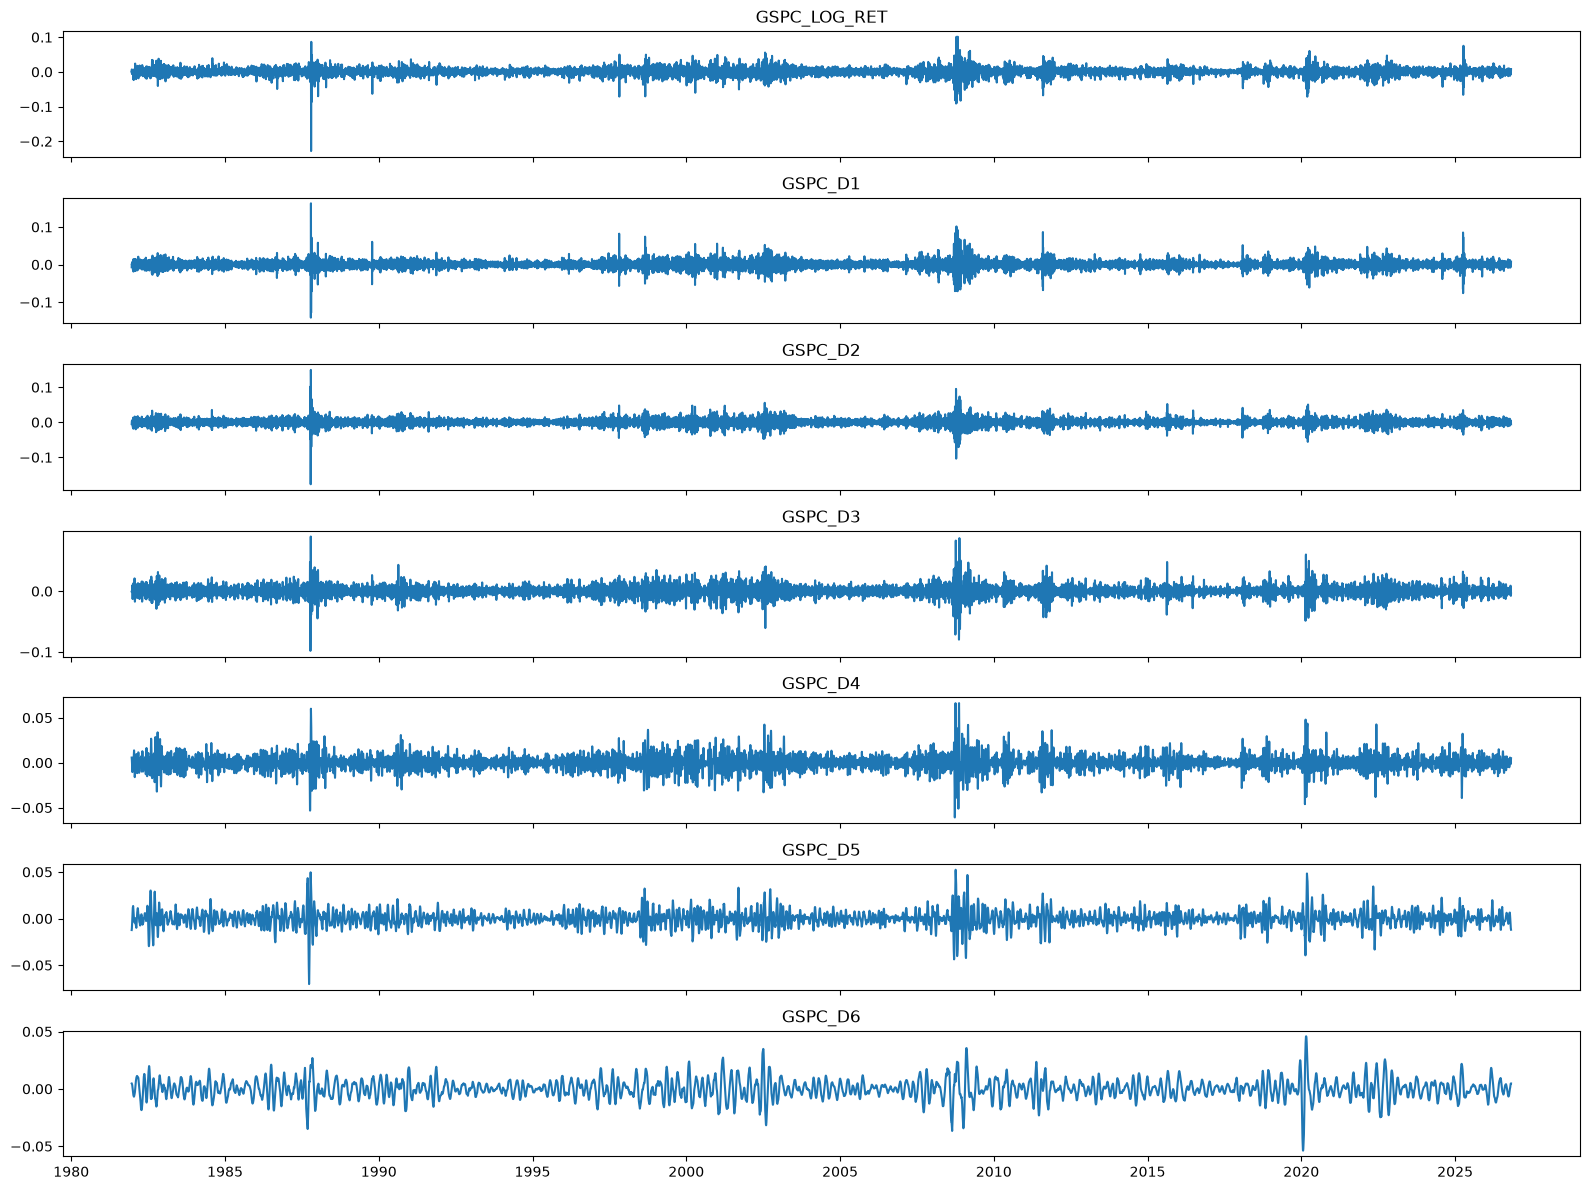

In [26]:
# SWT解析結果の可視化
components = [f"GSPC_D{i}"for i in range(1, MAX_LEVEL + 1)]
# 可視化するSWT成分を設定
fig, axes = plt.subplots(len(components) + 1, 1, figsize=(16, 12), sharex=True,)
# 元の信号をプロット
axes[0].plot(
    research_swt.index,
    research_swt["GSPC_LOG_RET"]
)
axes[0].set_title(
    "GSPC_LOG_RET"
)
# 各SWT成分をプロット
for i, component in enumerate(
    components
):
    axes[i + 1].plot(
        research_swt.index,
        research_swt[component]
    )
    axes[i + 1].set_title(
        component
    )
# レイアウトを調整して表示
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"5_visualize_wavelet_components_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# プロットを表示
plt.show()

#### 6. Merge Explanatory Variables

In [27]:
candidate_features = [
    "DFF",
    "DGS10",
    "DXY",
    "DFII10",
    "BAMLH0A0HYM2",
]
# 各候補特徴量を research_swt に追加
for feature in candidate_features:
    # market_df から対応する特徴量を取得して research_swt に追加
    research_swt[feature] = (
        market_df[feature]
    )
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_merge_explanatory_variables_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_swt.copy()
df.to_csv(output_path)
print("saved:", output_path)
# research_swt の末尾を表示
research_swt.tail()

saved: /workspace/data/6_merge_explanatory_variables_2026-10-28.csv


,GSPC,GSPC_LOG_RET,GSPC_D6,GSPC_D5,GSPC_D4,GSPC_D3,GSPC_D2,GSPC_D1,DFF,DGS10,DXY,DFII10,BAMLH0A0HYM2
date,,,,,,,,,,,,,
2026-10-23,7637.180176,-0.007493,0.004480,-0.010415,-0.001319,0.000585,0.001765,-0.003340,3.88,5.0,0.7037,2.66,3.38
2026-10-24,7637.180176,0.000000,0.004700,-0.011048,-0.000310,-0.004889,-0.003195,0.005231,3.88,5.0,0.7037,2.66,3.38
2026-10-25,7637.180176,0.000000,0.004721,-0.011290,0.001045,-0.007676,0.001141,-0.004622,3.88,5.0,0.7037,2.66,3.38
2026-10-26,7639.700195,0.000330,0.004680,-0.011355,0.002895,-0.006615,0.001018,-0.001718,3.88,5.0,0.7037,2.66,3.30
2026-10-27,7699.470215,0.007793,0.004709,-0.011973,0.004982,-0.003830,-0.005732,0.007788,3.88,5.0,0.7037,2.66,3.30


#### 7. Single Regression Analysis

In [28]:
# 各候補特徴量と各SWT成分の単回帰分析を実行し、結果をまとめる
results = []
# 各候補特徴量と各SWT成分の組み合わせについて、サンプル数が500以上の場合に単回帰分析を実行する
for feature in candidate_features:
    # 各SWT成分のレベルについてループ
    for level in range(1, MAX_LEVEL + 1):
        # 対象のSWT成分のカラム名を作成
        target = (f"GSPC_D{level}")
        # 
        tmp = (research_swt[[feature, target]].dropna())
        # サンプル数が500未満の場合はスキップ
        if len(tmp) < 500:
            continue
        # 単回帰分析を実行
        reg = linregress(tmp[feature], tmp[target])
        # 結果を辞書形式で保存
        results.append(
            {
                "feature": feature,
                "target": target,
                "r": reg.rvalue,
                "r2": reg.rvalue ** 2,
                "p_value": reg.pvalue,
                "n": len(tmp),
            }
        )
# 単回帰分析の結果をDataFrameに変換
single_regression_df = pd.DataFrame(results)
# r2の高い順に並べ替えて上位の結果を確認
single_regression_df = (
    single_regression_df
    .sort_values(
        "r2",
        ascending=False
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"7_single_regression_analysis_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = single_regression_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
# 上位30件を表示
single_regression_df.head(30)

saved: /workspace/data/7_single_regression_analysis_2026-10-28.csv


,feature,target,r,r2,p_value,n
29,BAMLH0A0HYM2,GSPC_D6,0.050325,2.532560e-03,0.096179,1094
24,BAMLH0A0HYM2,GSPC_D1,-0.023343,5.448970e-04,0.440524,1094
27,BAMLH0A0HYM2,GSPC_D4,0.018549,3.440580e-04,0.539965,1094
23,DFII10,GSPC_D6,0.017952,3.222671e-04,0.094066,8700
28,BAMLH0A0HYM2,GSPC_D5,-0.015561,2.421538e-04,0.607152,1094
25,BAMLH0A0HYM2,GSPC_D2,-0.012247,1.499956e-04,0.685743,1094
11,DGS10,GSPC_D6,0.005819,3.386484e-05,0.456377,16384
17,DXY,GSPC_D6,-0.004834,2.336698e-05,0.536113,16384
10,DGS10,GSPC_D5,0.004227,1.786905e-05,0.588480,16384
5,DFF,GSPC_D6,0.002583,6.672099e-06,0.740943,16384


#### 8. R² Heatmap

saved: /workspace/data/figures/8_feature_vs_wavelet_R2_1950-01-01_2026-10-28.png


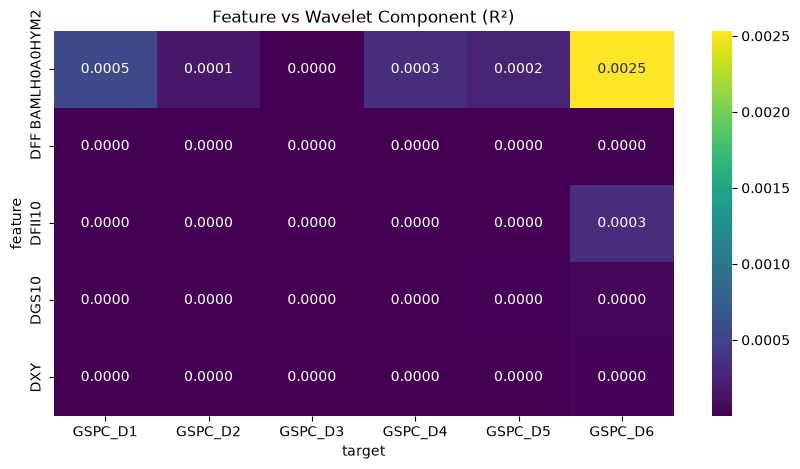

In [29]:
# 単回帰分析の結果をヒートマップで可視化する
heatmap_df = (
    single_regression_df
    .pivot(
        index="feature",
        columns="target",
        values="r2"
    )
)
# ヒートマップの描画
plt.figure(figsize=(10, 5))
# ヒートマップを描画するための準備
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".4f",
    cmap="viridis"
)
plt.title("Feature vs Wavelet Component (R²)")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"8_feature_vs_wavelet_R2_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# ヒートマップを表示
plt.show()

#### 9. Significant Relationships

In [30]:
significant_df = (
    single_regression_df[
        single_regression_df[
            "p_value"
        ] < 0.05
    ]
    .copy()
)
# 有意な結果のみを保存
significant_df = significant_df.sort_values("r2", ascending=False)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"9_single_relationships_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = significant_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
# 有意な結果の下位5件を表示
significant_df.tail()

saved: /workspace/data/9_single_relationships_2026-10-28.csv


,feature,target,r,r2,p_value,n


# Market Structure Multi-Scale Analysis V1
## Phase 1 : Wavelet Decomposition of S&P500

### 目的

長期金利、実質金利、ドル指数、信用スプレッド等のマクロ要因が、株価指数のどの時間スケールの変動を説明しているかを調査する。

### 実施内容

S&P500 (GSPC) を目的変数とし、

1. 価格系列をWavelet分解
2. 対数リターン系列へ変換し再度Wavelet分解
3. Wavelet成分(D1～D6)を目的変数
4. DFF, DGS10, DXY, DFII10, BAMLH0A0HYM2 を説明変数
5. 単回帰分析により説明力(R²)を測定

を実施した。

### 結果

価格系列を直接Wavelet分解した場合、長期上昇トレンドや境界効果の影響が大きく、解釈可能な結果は得られなかった。

そのため対数リターン系列へ変換して再検証したが、結果は本質的に変化しなかった。

全ての説明変数において R² は概ね 0.003 以下に留まり、同時点における説明力は極めて限定的であった。

### 考察

本検証によって、

「説明変数とWavelet成分との同時相関」

はほぼ存在しないことが確認された。

しかしこれは、

「説明変数が株価を説明しない」

ことを意味しない。

長期金利や信用スプレッドは企業収益や資金調達環境を経由して株価へ伝播するため、数か月から数年の時間遅延が存在する可能性が高い。

今回の分析は

X(t) → Y(t)

のみを評価しており、

X(t) → Y(t+lag)

は未検証である。

### 結論

Wavelet分解による時間スケール抽出は成功したが、マクロ要因との同時点回帰では有意な説明力は確認できなかった。

次の研究課題として、

「説明変数がどの時間スケールに対して、どの程度の遅延をもって影響するか」

を分析する必要がある。
